# PySpark Installation

PySpark 3.5.3

In [1]:
!pip install -q pyspark==3.5.3

Spark Session Setup & Google Cloud Authentication

In [2]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Soccer_EDA") \
    .master("local[*]") \
    .getOrCreate()

print("Spark version:", spark.version)

Spark version: 3.5.3


In [3]:
from google.colab import auth
auth.authenticate_user()


Access Cleaned Data from GCS

In [4]:
from google.cloud import storage

client = storage.Client(project="ba-843-1011011")
bucket = client.bucket("qst5project")

blobs = list(bucket.list_blobs(
    prefix="statsbomb/clean/test/events_clean/",
    max_results=5
))

for blob in blobs:
    print(blob.name)

statsbomb/clean/test/events_clean/_SUCCESS
statsbomb/clean/test/events_clean/part-00000-453da000-63b9-4e01-beb8-9d3755a98745-c000.snappy.parquet
statsbomb/clean/test/events_clean/part-00001-453da000-63b9-4e01-beb8-9d3755a98745-c000.snappy.parquet


Load Cleaned Data into PySpark

In [5]:
import os

local_dir = "/content/soccer_data/events_clean"
os.makedirs(local_dir, exist_ok=True)

prefix = "statsbomb/clean/test/events_clean/"

for blob in bucket.list_blobs(prefix=prefix):
    if blob.name.endswith(".parquet"):
        filename = os.path.basename(blob.name)
        blob.download_to_filename(
            os.path.join(local_dir, filename)
        )

events_clean = spark.read.parquet(local_dir)

print("Total events:", events_clean.count())
events_clean.printSchema()

Total events: 455936
root
 |-- event_id: string (nullable = true)
 |-- match_id: integer (nullable = true)
 |-- event_index: long (nullable = true)
 |-- period: long (nullable = true)
 |-- minute: long (nullable = true)
 |-- second: long (nullable = true)
 |-- event_type: string (nullable = true)
 |-- team: string (nullable = true)
 |-- player_id: long (nullable = true)
 |-- player: string (nullable = true)
 |-- position: string (nullable = true)
 |-- x: double (nullable = true)
 |-- y: double (nullable = true)
 |-- under_pressure: boolean (nullable = true)
 |-- pass_end_x: double (nullable = true)
 |-- pass_end_y: double (nullable = true)
 |-- pass_outcome: string (nullable = true)
 |-- carry_end_x: double (nullable = true)
 |-- carry_end_y: double (nullable = true)
 |-- dribble_outcome: string (nullable = true)
 |-- shot_xg: double (nullable = true)
 |-- shot_outcome: string (nullable = true)
 |-- competition: string (nullable = true)
 |-- season: string (nullable = true)
 |-- gender

Explore Event Types

In [6]:
from pyspark.sql import functions as F

events_clean.groupBy("event_type") \
    .count() \
    .orderBy(F.desc("count")) \
    .show(50, truncate=False)

+----------------+------+
|event_type      |count |
+----------------+------+
|Pass            |128295|
|Ball Receipt*   |120335|
|Carry           |100536|
|Pressure        |40997 |
|Ball Recovery   |14286 |
|Duel            |9495  |
|Clearance       |5965  |
|Block           |5419  |
|Miscontrol      |4162  |
|Dribble         |3956  |
|Goal Keeper     |3779  |
|Dispossessed    |3416  |
|Foul Committed  |3194  |
|Shot            |3087  |
|Foul Won        |3015  |
|Interception    |2762  |
|Dribbled Past   |2274  |
|50/50           |607   |
|Shield          |232   |
|Error           |64    |
|Offside         |49    |
|Own Goal Against|11    |
+----------------+------+



Explore Player Positions and Actions

In [7]:
events_clean.groupBy("position", "event_type") \
    .count() \
    .orderBy("position", F.desc("count")) \
    .show(60, truncate=False)

+-------------------------+----------------+-----+
|position                 |event_type      |count|
+-------------------------+----------------+-----+
|Center Attacking Midfield|Ball Receipt*   |4950 |
|Center Attacking Midfield|Pass            |4075 |
|Center Attacking Midfield|Carry           |3705 |
|Center Attacking Midfield|Pressure        |2272 |
|Center Attacking Midfield|Ball Recovery   |607  |
|Center Attacking Midfield|Duel            |407  |
|Center Attacking Midfield|Dispossessed    |276  |
|Center Attacking Midfield|Miscontrol      |262  |
|Center Attacking Midfield|Dribble         |262  |
|Center Attacking Midfield|Block           |220  |
|Center Attacking Midfield|Shot            |176  |
|Center Attacking Midfield|Foul Won        |171  |
|Center Attacking Midfield|Foul Committed  |131  |
|Center Attacking Midfield|Dribbled Past   |80   |
|Center Attacking Midfield|Clearance       |78   |
|Center Attacking Midfield|Interception    |70   |
|Center Attacking Midfield|50/5

Identify Player Positions

In [8]:
events_clean.select("position") \
    .distinct() \
    .orderBy("position") \
    .show(100, truncate=False)

+-------------------------+
|position                 |
+-------------------------+
|Center Attacking Midfield|
|Center Back              |
|Center Defensive Midfield|
|Center Forward           |
|Goalkeeper               |
|Left Attacking Midfield  |
|Left Back                |
|Left Center Back         |
|Left Center Forward      |
|Left Center Midfield     |
|Left Defensive Midfield  |
|Left Midfield            |
|Left Wing                |
|Left Wing Back           |
|Right Attacking Midfield |
|Right Back               |
|Right Center Back        |
|Right Center Forward     |
|Right Center Midfield    |
|Right Defensive Midfield |
|Right Midfield           |
|Right Wing               |
|Right Wing Back          |
+-------------------------+



Group Player Positions

In [9]:
from pyspark.sql import functions as F

events_eda = events_clean.withColumn(
    "position_group",
    F.when(F.col("position") == "Goalkeeper", "Goalkeeper")
     .when(F.col("position").contains("Back"), "Defender")
     .when(F.col("position").contains("Midfield"), "Midfielder")
     .when(
         F.col("position").contains("Forward") |
         F.col("position").contains("Wing"),
         "Forward"
     )
     .otherwise("Other")
)

events_eda.groupBy("position_group") \
    .count() \
    .orderBy("position_group") \
    .show()

+--------------+------+
|position_group| count|
+--------------+------+
|      Defender|188555|
|       Forward| 94036|
|    Goalkeeper| 19959|
|    Midfielder|153386|
+--------------+------+



# EDA

##1.How do player actions differ by position?

**Objective:** To compare passing, carrying, and pressing activities among defenders, midfielders, and forwards. This helps us understand how players in different positions contribute to the game beyond goals and assists.

**Method:** I group players into four position categories: Defenders, Midfielders, Forwards, and Goalkeepers. I then calculate the percentage of passes, carries, and pressures out of all recorded events for each position group.

**Visualization:** Grouped Bar Chart.

In [10]:
actions = ["Pass", "Carry", "Pressure"]

action_count = events_eda.filter(F.col("event_type").isin(actions))
action_count = action_count.groupBy("position_group", "event_type").count()
action_count.orderBy("position_group", "event_type").show(20)

+--------------+----------+-----+
|position_group|event_type|count|
+--------------+----------+-----+
|      Defender|     Carry|44506|
|      Defender|      Pass|62042|
|      Defender|  Pressure|12136|
|       Forward|     Carry|18412|
|       Forward|      Pass|18060|
|       Forward|  Pressure|11610|
|    Goalkeeper|     Carry| 3786|
|    Goalkeeper|      Pass| 7790|
|    Goalkeeper|  Pressure|   21|
|    Midfielder|     Carry|33832|
|    Midfielder|      Pass|40403|
|    Midfielder|  Pressure|17230|
+--------------+----------+-----+



In [11]:
position_total = events_eda.groupBy("position_group").count().withColumnRenamed("count", "total")

action_pct = action_count.join(position_total, "position_group")
action_pct = action_pct.withColumn("percentage", F.round(F.col("count") / F.col("total") * 100, 2))

action_pct.orderBy("position_group", "event_type").show(20)

+--------------+----------+-----+------+----------+
|position_group|event_type|count| total|percentage|
+--------------+----------+-----+------+----------+
|      Defender|     Carry|44506|188555|      23.6|
|      Defender|      Pass|62042|188555|      32.9|
|      Defender|  Pressure|12136|188555|      6.44|
|       Forward|     Carry|18412| 94036|     19.58|
|       Forward|      Pass|18060| 94036|     19.21|
|       Forward|  Pressure|11610| 94036|     12.35|
|    Goalkeeper|     Carry| 3786| 19959|     18.97|
|    Goalkeeper|      Pass| 7790| 19959|     39.03|
|    Goalkeeper|  Pressure|   21| 19959|      0.11|
|    Midfielder|     Carry|33832|153386|     22.06|
|    Midfielder|      Pass|40403|153386|     26.34|
|    Midfielder|  Pressure|17230|153386|     11.23|
+--------------+----------+-----+------+----------+



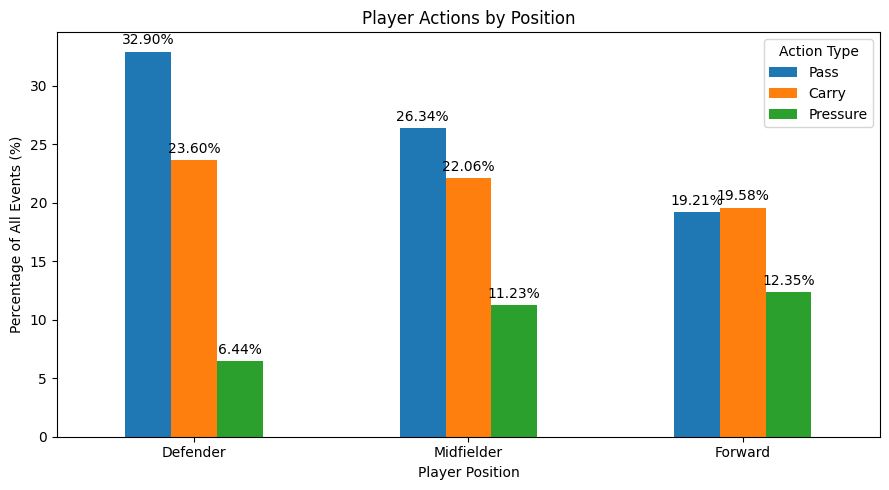

In [12]:
import matplotlib.pyplot as plt

df = action_pct.toPandas()
df = df.pivot(index="position_group", columns="event_type", values="percentage")
df = df.reindex(["Defender", "Midfielder", "Forward"])

ax = df[["Pass", "Carry", "Pressure"]].plot(kind="bar", figsize=(9, 5))

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Player Actions by Position")
plt.xlabel("Player Position")
plt.ylabel("Percentage of All Events (%)")
plt.xticks(rotation=0)
plt.legend(title="Action Type")
plt.tight_layout()
plt.show()

There are three specific findings:
1. Defenders account for the highest share of both passes (32.90%) and carries (23.60%), indicating that passing and carrying the ball are significant components of their recorded actions.
2. Midfielders account for 26.34% of passes and 11.23% of pressing actions, reflecting their involvement in a diverse range of activities.
3. Forwards account for the highest share of pressing actions (12.35%) but the lowest share of passes (19.21%). This suggests that, beyond finishing attacks, forwards also contribute by applying defensive pressure.

These differences suggest that goals and assists alone may not fully capture a player's contribution. When evaluating a player, one should also consider their position on the pitch and other aspects of their performance during a match.

##2.Which players make the most progressive passes and carries?

Objective: To identify players who contribute to moving the ball forward through passes and carries. This helps me explore player contributions beyond traditional statistics such as goals and assists.

Method: I calculate the forward distance of each pass and carry using the starting and ending coordinates. For this analysis, I define a progressive action as a pass or carry that moves the ball forward by at least 10 StatsBomb coordinate units. I then count these actions for each player and rank the players by their total progressive actions.

Visualization: Horizontal Stacked Bar Chart showing the top 10 players by progressive passes and carries.

In [13]:
events_clean.filter(F.col("event_type").isin("Pass", "Carry")).select(
    "event_type", "player", "x", "y",
    "pass_end_x", "pass_end_y",
    "carry_end_x", "carry_end_y"
).show(10, truncate=False)

+----------+-----------------------+----+----+----------+----------+-----------+-----------+
|event_type|player                 |x   |y   |pass_end_x|pass_end_y|carry_end_x|carry_end_y|
+----------+-----------------------+----+----+----------+----------+-----------+-----------+
|Pass      |Andrej Kramarić        |61.0|40.1|38.0      |48.1      |NULL       |NULL       |
|Carry     |Dejan Lovren           |38.0|48.1|NULL      |NULL      |36.9       |46.4       |
|Pass      |Dejan Lovren           |36.9|46.4|96.8      |32.5      |NULL       |NULL       |
|Pass      |Nicolás Hernán Otamendi|23.3|47.6|46.8      |40.3      |NULL       |NULL       |
|Carry     |Alexis Mac Allister    |46.8|40.3|NULL      |NULL      |47.0       |40.1       |
|Pass      |Marcelo Brozović       |62.2|41.0|45.9      |42.8      |NULL       |NULL       |
|Carry     |Dejan Lovren           |45.9|42.8|NULL      |NULL      |45.5       |42.8       |
|Pass      |Dejan Lovren           |45.5|42.8|49.5      |65.5      |NU

In [14]:
progression = events_clean.filter(F.col("event_type").isin("Pass", "Carry"))

progression = progression.withColumn("end_x", F.when(F.col("event_type") == "Pass", F.col("pass_end_x")).otherwise(F.col("carry_end_x")))
progression = progression.withColumn("forward_distance", F.round(F.col("end_x") - F.col("x"), 2))

progression.select("player", "event_type", "x", "end_x", "forward_distance").show(15, truncate=False)

+-----------------------+----------+----+-----+----------------+
|player                 |event_type|x   |end_x|forward_distance|
+-----------------------+----------+----+-----+----------------+
|Andrej Kramarić        |Pass      |61.0|38.0 |-23.0           |
|Dejan Lovren           |Carry     |38.0|36.9 |-1.1            |
|Dejan Lovren           |Pass      |36.9|96.8 |59.9            |
|Nicolás Hernán Otamendi|Pass      |23.3|46.8 |23.5            |
|Alexis Mac Allister    |Carry     |46.8|47.0 |0.2             |
|Marcelo Brozović       |Pass      |62.2|45.9 |-16.3           |
|Dejan Lovren           |Carry     |45.9|45.5 |-0.4            |
|Dejan Lovren           |Pass      |45.5|49.5 |4.0             |
|Josip Juranović        |Carry     |49.5|49.0 |-0.5            |
|Josip Juranović        |Pass      |49.0|40.4 |-8.6            |
|Dejan Lovren           |Carry     |40.4|41.0 |0.6             |
|Dejan Lovren           |Pass      |41.0|50.8 |9.8             |
|Borna Sosa             |

In [15]:
progressive_actions = progression.filter(
    (F.col("forward_distance") >= 10) &
    ((F.col("event_type") == "Carry") |
     ((F.col("event_type") == "Pass") & (F.col("pass_outcome") == "Complete")))
)

progressive_actions.groupBy("event_type").count().show()

+----------+-----+
|event_type|count|
+----------+-----+
|     Carry| 9802|
|      Pass|28872|
+----------+-----+



In [16]:
player_progress = progressive_actions.groupBy("player", "event_type").count()
player_progress = player_progress.groupBy("player").pivot("event_type", ["Pass", "Carry"]).sum("count").fillna(0)

player_progress = player_progress.withColumn("total", F.col("Pass") + F.col("Carry"))
player_progress.orderBy(F.desc("total")).show(15, truncate=False)

+--------------------------+----+-----+-----+
|player                    |Pass|Carry|total|
+--------------------------+----+-----+-----+
|Alex Greenwood            |206 |48   |254  |
|Rodrigo Hernández Cascante|175 |73   |248  |
|Irene Paredes Hernandez   |200 |48   |248  |
|Millie Bright             |177 |44   |221  |
|Joško Gvardiol            |168 |46   |214  |
|Luka Modrić               |152 |51   |203  |
|John Stones               |148 |47   |195  |
|Nicolás Hernán Otamendi   |155 |40   |195  |
|Dejan Lovren              |139 |41   |180  |
|Ona Batlle Pascual        |118 |58   |176  |
|Harry Maguire             |127 |43   |170  |
|Magdalena Lilly Eriksson  |137 |26   |163  |
|Aymeric Laporte           |111 |44   |155  |
|Jessica Carter            |111 |40   |151  |
|Gun Nathalie Björn        |121 |28   |149  |
+--------------------------+----+-----+-----+
only showing top 15 rows



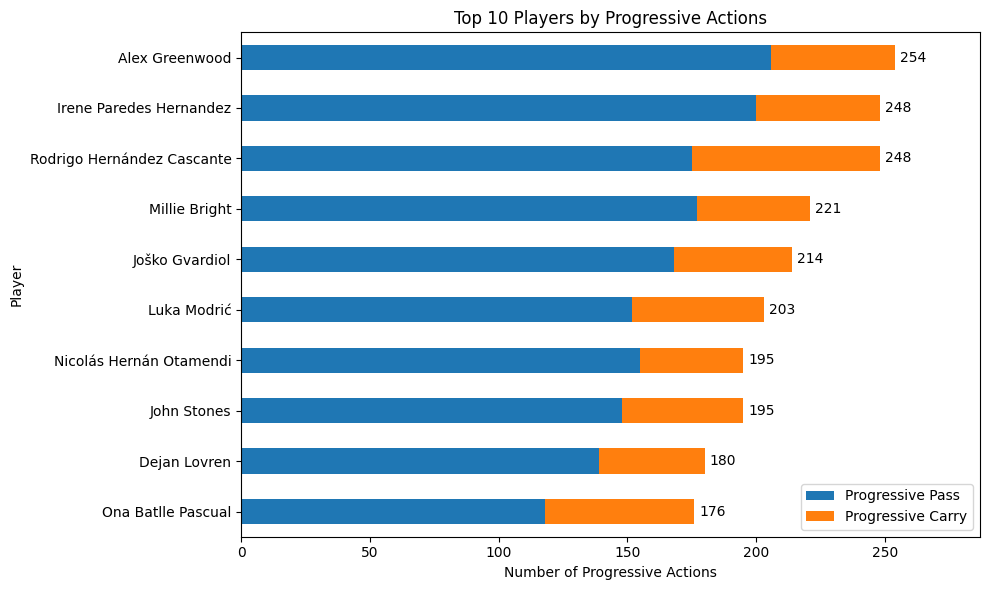

In [17]:
import matplotlib.pyplot as plt

top10 = player_progress.orderBy(F.desc("total")).limit(10).toPandas()
top10 = top10.sort_values("total")

ax = top10.plot.barh(x="player", y=["Pass", "Carry"], stacked=True, figsize=(10, 6))

for i, total in enumerate(top10["total"]):
    ax.text(total + 2, i, str(total), va="center")

plt.title("Top 10 Players by Progressive Actions")
plt.xlabel("Number of Progressive Actions")
plt.ylabel("Player")
plt.legend(["Progressive Pass", "Progressive Carry"])
plt.xlim(0, top10["total"].max() * 1.13)
plt.tight_layout()
plt.show()

Key findings from this chart:


Alex Greenwood ranks first with 254 progressive actions, followed by Irene Paredes Hernandez and Rodrigo Hernández Cascante, both with 248.

The top 10 includes several defenders and midfielders, such as Millie Bright, Joško Gvardiol, and Luka Modrić. This shows that moving the ball forward is not only the responsibility of forwards.

Progressive passes are the main type of progressive action among the top 10 players. All 10 players recorded more progressive passes than carries.

Defenders and midfielders can contribute to the attack through successful forward passes and progressive carries, even when these actions do not directly result in a goal or an assist. This aligns with our project’s objective: to evaluate players by looking beyond traditional statistics.

However, since these rankings are based on the total volume of actions—without any adjustment for playing time—they do not serve as a direct measure of a player’s efficiency, nor do they prove that a particular player is underrated.

##3.Where on the Field Do Progressive Actions Happen Most Often?

Objective: To identify where progressive passes and carries most frequently start on the field. This helps me understand how players contribute to moving the ball forward from different areas.

Method: I use the starting coordinates of progressive passes and carries from the cleaned StatsBomb data. I define a progressive action as a pass or carry that moves the ball forward by at least 10 coordinate units. I divide the 120 × 80 pitch into 10 × 10 zones and count the number of progressive actions starting in each zone.

Visualization: Soccer Pitch Heatmap showing the starting locations of progressive actions.

In [18]:
progressive_actions.select("event_type", "x", "y", "forward_distance").show(10, truncate=False)

progressive_actions.select(
    F.min("x").alias("min_x"),
    F.max("x").alias("max_x"),
    F.min("y").alias("min_y"),
    F.max("y").alias("max_y")
).show()

+----------+----+----+----------------+
|event_type|x   |y   |forward_distance|
+----------+----+----+----------------+
|Pass      |23.3|47.6|23.5            |
|Pass      |12.8|43.2|14.4            |
|Carry     |16.0|59.9|25.1            |
|Carry     |34.5|26.8|11.7            |
|Carry     |35.4|29.9|12.9            |
|Carry     |20.5|48.8|27.3            |
|Pass      |53.3|75.2|64.4            |
|Carry     |44.2|52.5|20.7            |
|Pass      |13.5|33.4|16.4            |
|Pass      |29.6|21.3|15.7            |
+----------+----+----+----------------+
only showing top 10 rows

+-----+-----+-----+-----+
|min_x|max_x|min_y|max_y|
+-----+-----+-----+-----+
|  0.2|109.3|  0.1| 80.0|
+-----+-----+-----+-----+



In [19]:
pitch_data = progressive_actions.withColumn("x_zone", F.floor(F.col("x") / 10))
pitch_data = pitch_data.withColumn("y_zone", F.floor(F.col("y") / 10))

pitch_count = pitch_data.groupBy("x_zone", "y_zone").count()
pitch_count.orderBy(F.desc("count")).show(15)

+------+------+-----+
|x_zone|y_zone|count|
+------+------+-----+
|     0|     4|  914|
|     5|     2|  847|
|     4|     2|  792|
|     0|     3|  790|
|     4|     5|  787|
|     5|     5|  776|
|     3|     2|  766|
|     3|     5|  764|
|     5|     1|  747|
|     5|     4|  711|
|     2|     2|  695|
|     1|     4|  691|
|     6|     2|  682|
|     5|     3|  680|
|     2|     5|  660|
+------+------+-----+
only showing top 15 rows



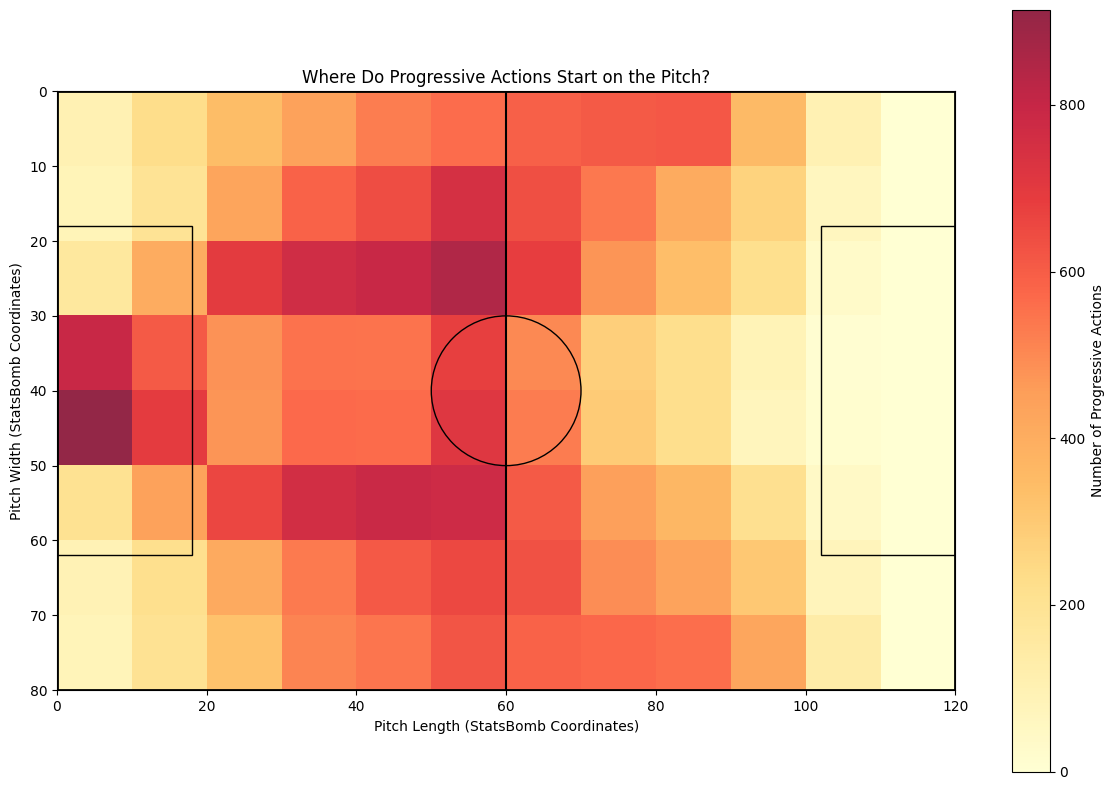

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle, Circle, Arc

df = pitch_count.toPandas()
heatmap = np.zeros((8, 12))

for _, row in df.iterrows():
    x = min(int(row["x_zone"]), 11)
    y = min(int(row["y_zone"]), 7)
    heatmap[y, x] += row["count"]

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(heatmap, extent=[0, 120, 80, 0], cmap="YlOrRd", alpha=0.85)
ax.add_patch(Rectangle((0, 0), 120, 80, fill=False, edgecolor="black", linewidth=2))
ax.plot([60, 60], [0, 80], color="black")
ax.add_patch(Circle((60, 40), 10, fill=False, edgecolor="black"))
ax.add_patch(Rectangle((0, 18), 18, 44, fill=False, edgecolor="black"))
ax.add_patch(Rectangle((102, 18), 18, 44, fill=False, edgecolor="black"))

plt.colorbar(ax.images[0], ax=ax, label="Number of Progressive Actions")
plt.title("Where Do Progressive Actions Start on the Pitch?")
plt.xlabel("Pitch Length (StatsBomb Coordinates)")
plt.ylabel("Pitch Width (StatsBomb Coordinates)")
plt.tight_layout()
plt.show()

The highest number of attacking progressions (914) originated from the defensive and middle-third zones, indicating that many forward-moving attacks began within the team's own half.

A significant number of attacking progressions also originated from the midfield zone. The two subsequent zones recorded 847 and 792 such actions, respectively, demonstrating that the team’s attacking progressions are distributed across various areas of the pitch.

Attacking progressions initiated near the opponent's goal were relatively infrequent. One possible reason for this is that, in that area, there is limited space to develop an attack by advancing at least 10 coordinate units forward.

Attacking progression often begins in the defensive or midfield thirds, rather than occurring solely when forwards approach the goal. While traditional metrics like goals and assists capture the final outcomes of an attack, defenders and midfielders frequently contribute to the build-up phase through forward passes or carries—contributions that are not necessarily reflected in goal or assist statistics.
Therefore, when evaluating players, one should look beyond just goals and assists and also examine the roles they play in advancing the attack.
It should be noted, however, that this chart only tracks the starting points and frequency of these progressive actions; it does not prove that these actions led to scoring opportunities, nor does it serve as definitive evidence that a particular player is underrated.